In [1]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        print(os.path.join(root, file))

/content/archive (3).zip
/content/.config/default_configs.db
/content/.config/gce
/content/.config/.last_opt_in_prompt.yaml
/content/.config/active_config
/content/.config/.last_survey_prompt.yaml
/content/.config/.last_update_check.json
/content/.config/config_sentinel
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/configurations/config_default
/content/.config/logs/2026.10.02/13.50.14.261149.log
/content/.config/logs/2026.10.02/13.50.21.555054.log
/content/.config/logs/2026.10.02/13.50.08.874802.log
/content/.config/logs/2026.10.02/13.50.15.366402.log
/content/.config/logs/2026.10.02/13.50.21.004336.log
/content/.config/logs/2026.10.02/13.49.46.128557.log
/content/sample_data/anscombe.json
/content/sample_data/README.md
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [2]:
import zipfile
import os

zip_path = "/content/archive (3).zip"
extract_path = "/content/customer_intent"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Dataset extracted successfully!
/content/customer_intent/Bitext_Sample_Customer_Service_Training_Dataset.csv
/content/customer_intent/Bitext_Sample_Customer_Service_Testing_Dataset.csv
/content/customer_intent/Bitext_Sample_Customer_Service_Validation_Dataset.csv


In [3]:
import os

folder = "/content/customer_intent"

for root, dirs, files in os.walk(folder):
    for file in files:
        print("File name:", file)

File name: Bitext_Sample_Customer_Service_Training_Dataset.csv
File name: Bitext_Sample_Customer_Service_Testing_Dataset.csv
File name: Bitext_Sample_Customer_Service_Validation_Dataset.csv


In [4]:
import pandas as pd
import glob
import os

files = glob.glob("/content/customer_intent/**/*", recursive=True)

for file in files:
    if file.endswith(".csv"):
        print("CSV file:", file)
        df = pd.read_csv(file)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))

CSV file: /content/customer_intent/Bitext_Sample_Customer_Service_Training_Dataset.csv
Shape: (6539, 4)
Columns: ['utterance', 'intent', 'category', 'tags']


,utterance,intent,category,tags
0,would it be possible to cancel the order I made?,cancel_order,ORDER,BIP
1,cancelling order,cancel_order,ORDER,BK
2,I need assistance canceling the last order I h...,cancel_order,ORDER,B
3,problem with canceling the order I made,cancel_order,ORDER,B
4,I don't know how to cancel the order I made,cancel_order,ORDER,B


CSV file: /content/customer_intent/Bitext_Sample_Customer_Service_Testing_Dataset.csv
Shape: (818, 4)
Columns: ['utterance', 'intent', 'category', 'tags']


,utterance,intent,category,tags
0,I have a question about cancelling an order,cancel_order,ORDER,B
1,help canceling the order I have made,cancel_order,ORDER,B
2,I do not know how to cancel an order I have made,cancel_order,ORDER,BE
3,where can I cancel the last order I made?,cancel_order,ORDER,BI
4,I don't want the last order I made,cancel_order,ORDER,B


CSV file: /content/customer_intent/Bitext_Sample_Customer_Service_Validation_Dataset.csv
Shape: (818, 4)
Columns: ['utterance', 'intent', 'category', 'tags']


,utterance,intent,category,tags
0,I want help to cancel the order I have made,cancel_order,ORDER,B
1,where can I get information about order cancel...,cancel_order,ORDER,BIM
2,help to cancel the last order,cancel_order,ORDER,B
3,I need help with canceling an order I made,cancel_order,ORDER,B
4,I do not know how I can cancel the order I made,cancel_order,ORDER,BE


In [5]:
import os
import glob
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

folder = "/content/customer_intent"

csv_files = glob.glob(
    folder + "/**/*.csv",
    recursive=True
)

print("CSV files found:")
for file in csv_files:
    print(file)

if not csv_files:
    raise FileNotFoundError("No CSV files found. Check the extracted files.")

# Prefer a training file if one exists
train_files = [
    f for f in csv_files
    if "train" in os.path.basename(f).lower()
]

if train_files:
    data_file = train_files[0]
else:
    data_file = max(csv_files, key=os.path.getsize)

df = pd.read_csv(data_file)

print("\nSelected file:", data_file)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

CSV files found:
/content/customer_intent/Bitext_Sample_Customer_Service_Training_Dataset.csv
/content/customer_intent/Bitext_Sample_Customer_Service_Testing_Dataset.csv
/content/customer_intent/Bitext_Sample_Customer_Service_Validation_Dataset.csv

Selected file: /content/customer_intent/Bitext_Sample_Customer_Service_Training_Dataset.csv
Dataset shape: (6539, 4)
Columns: ['utterance', 'intent', 'category', 'tags']


,utterance,intent,category,tags
0,would it be possible to cancel the order I made?,cancel_order,ORDER,BIP
1,cancelling order,cancel_order,ORDER,BK
2,I need assistance canceling the last order I h...,cancel_order,ORDER,B
3,problem with canceling the order I made,cancel_order,ORDER,B
4,I don't know how to cancel the order I made,cancel_order,ORDER,B


In [6]:
print("Available columns:", df.columns.tolist())

# Find likely text columns
text_options = [
    "instruction", "text", "utterance",
    "query", "message", "customer_text"
]

# Find likely target columns
label_options = [
    "intent", "sentiment", "label",
    "target", "category"
]

text_col = next(
    (c for c in text_options if c in df.columns),
    None
)

label_col = next(
    (c for c in label_options if c in df.columns),
    None
)

if text_col is None or label_col is None:
    raise ValueError(
        "Could not automatically identify the text and label columns. "
        "Check the printed column names and set text_col and label_col manually."
    )

# Prefer intent for this customer-support intent dataset
if "intent" in df.columns:
    label_col = "intent"

df = df[[text_col, label_col]].copy()
df = df.dropna()

df[text_col] = df[text_col].astype(str).str.strip()
df[label_col] = df[label_col].astype(str).str.strip()

df = df[
    (df[text_col] != "") &
    (df[label_col] != "")
]

print("Input text column:", text_col)
print("Target column:", label_col)
print("Cleaned dataset shape:", df.shape)
print("\nLabel distribution:")
print(df[label_col].value_counts())

display(df.head())

Available columns: ['utterance', 'intent', 'category', 'tags']
Input text column: utterance
Target column: intent
Cleaned dataset shape: (6539, 2)

Label distribution:
intent
get_invoice                 268
payment_issue               263
check_invoice               258
contact_customer_service    253
complaint                   252
review                      248
check_payment_methods       246
set_up_shipping_address     246
check_cancellation_fee      246
cancel_order                246
track_order                 245
place_order                 243
check_refund_policy         240
get_refund                  239
registration_problems       239
track_refund                239
recover_password            239
newsletter_subscription     238
create_account              237
delivery_period             236
delete_account              236
delivery_options            236
edit_account                233
change_order                232
change_shipping_address     228
switch_account           

,utterance,intent
0,would it be possible to cancel the order I made?,cancel_order
1,cancelling order,cancel_order
2,I need assistance canceling the last order I h...,cancel_order
3,problem with canceling the order I made,cancel_order
4,I don't know how to cancel the order I made,cancel_order


In [7]:
X = df[text_col]
y = df[label_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5231
Testing samples: 1308


In [8]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=20000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [9]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model accuracy: {accuracy:.4f}")
print(f"Model accuracy percentage: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Model accuracy: 0.9939
Model accuracy percentage: 99.39%

Classification Report:
                          precision    recall  f1-score   support

            cancel_order       0.98      0.98      0.98        49
            change_order       1.00      0.98      0.99        46
 change_shipping_address       1.00      1.00      1.00        45
  check_cancellation_fee       0.98      1.00      0.99        49
           check_invoice       1.00      1.00      1.00        52
   check_payment_methods       1.00      1.00      1.00        49
     check_refund_policy       0.98      1.00      0.99        48
               complaint       1.00      1.00      1.00        50
contact_customer_service       1.00      1.00      1.00        51
     contact_human_agent       1.00      1.00      1.00        45
          create_account       0.98      0.96      0.97        47
          delete_account       1.00      0.98      0.99        47
        delivery_options       1.00      1.00      1.00     

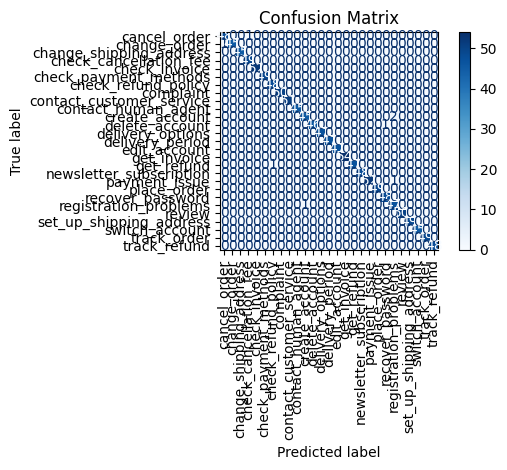

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation="vertical",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
def predict_customer_text(text):
    prediction = model.predict([text])[0]

    print("Customer input:", text)
    print("Predicted label:", prediction)

    return prediction

# Try a new customer message
predict_customer_text(
    "I want to cancel my order"
)

Customer input: I want to cancel my order
Predicted label: cancel_order


'cancel_order'

In [12]:
predict_customer_text(
    "I need help tracking my delivery"
)

predict_customer_text(
    "I was charged twice for my purchase"
)

predict_customer_text(
    "How can I reset my password?"
)

Customer input: I need help tracking my delivery
Predicted label: track_order
Customer input: I was charged twice for my purchase
Predicted label: create_account
Customer input: How can I reset my password?
Predicted label: recover_password


'recover_password'

In [13]:
import joblib

joblib.dump(model, "/content/customer_intent_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [14]:
from google.colab import files

files.download("/content/customer_intent_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>